# Import and export

CyteArc reads common single-cell count formats, writes a Zarr store for analysis, and exports counts or metadata to interoperable formats.
Most imports follow the same pattern: inspect when the source layout can vary, open a reader, then call a matching `*ToZarr` writer.

| Source | Inspect | Reader | Writer |
|---|---|---|---|
| 10x HDF5 | (inferred by reader) | `CrH5Reader` | `CrToZarr` |
| Matrix Market / MEX | `inspect_mtx` | `MtxReader` | `MtxToZarr` |
| AnnData H5AD | `inspect_h5ad` | `H5adReader` | `H5adToZarr` |
| Seurat RDS | `inspect_seurat` | `SeuratReader` | `SeuratToZarr` |
| Dense CSV | | `CSVReader` | `CSVtoZarr` |
| SciPy CSR | | | `SparseToZarr` |

Export paths write Matrix Market or H5AD.
CyteArc does not write Seurat `.rds` or `.h5seurat` files.
See [](../scanpy.md) or [](../seurat.md) for ecosystem-specific workflow mapping.

Start with the Matrix Market example below. The later sections cover other input formats and
show how to keep supplied analysis results or handle a larger import.

## Download example datasets

CyteArc hosts example datasets in the public [CyteBase bucket](https://huggingface.co/buckets/Nygen/cytebase) in formats such as MTX, 10x HDF5, and H5AD.
Connect to the `cytearc_docs` repository to download them:

In [1]:
# Manage local file and directory paths.
from pathlib import Path

# Create temporary directories for this example.
from tempfile import TemporaryDirectory

# Work with numeric arrays and cell masks.
import numpy as np

# Summarize inspected files and matrices in tables.
import pandas as pd

# Open count stores and run CyteArc analyses.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="ERROR", progress=False)

# Connect to the public example-data repository.
datasets = cytearc.cytebase.connect("cytearc_docs")

# Keep this tutorial's temporary files together.
outputs = TemporaryDirectory()

# Use the temporary directory for downloads and conversions.
output_dir = Path(outputs.name)

# Show the local path used by this step.
output_dir

PosixPath('/tmp/tmp3u289617')

Started: 2026-10-22T16:51:53.572063Z | Wall time: 1.049 s

**Naming format**: `<author>_<number of cells>_<cell/tissue type or species>_<single-cell method>`

Each download returns the directory it wrote, which the readers below use as their input path.

In [2]:
# Download the Matrix Market example.
mtx_dir = datasets.download_dataset(
    name="xin_1K_pancreas_rnaseq",
    destination=output_dir,
)

# Show the local path used by this step.
mtx_dir

PosixPath('/tmp/tmp3u289617/xin_1K_pancreas_rnaseq')

Started: 2026-10-22T16:51:54.623462Z | Wall time: 3.057 s

This tutorial writes downloads and converted stores below one temporary directory. Replace
`output_dir` with a persistent project directory in your own workflow.

## Import Matrix Market

A Matrix Market import needs three matching files: the count matrix, feature identifiers,
and cell barcodes. `inspect_mtx` finds complete triplets and reports their dimensions. If the
source contains both raw and filtered matrices, compare the candidates and choose which cells
to import; inspection does not make that choice for you.

A source can be an `.mtx` or `.mtx.gz` file, a directory, or a direct MEX ZIP.
Inspection recognizes canonical 10x names, common prefixed triplets, and Parse DGE directories.

In [3]:
# Find complete matrix, feature, and cell-file triplets.
candidates = cytearc.inspect_mtx(str(mtx_dir))

# Compare the candidate files and dimensions without repeating the download path.
pd.DataFrame(
    {
        index: {
            "matrix file": str(Path(candidate.matrixPath).relative_to(mtx_dir)),
            "feature file": str(Path(candidate.featurePath).relative_to(mtx_dir)),
            "cell file": str(Path(candidate.cellPath).relative_to(mtx_dir)),
            "orientation": candidate.matrixOrientation,
            "cells": candidate.nCells,
            "features": candidate.nFeatures,
            "stored entries": candidate.nEntries,
        }
        for index, candidate in enumerate(candidates)
    }
).rename_axis(columns="candidate")

candidate,0
matrix file,matrix.mtx.gz
feature file,features.tsv.gz
cell file,barcodes.tsv.gz
orientation,featuresByCells
cells,1600
features,39846
stored entries,9160987


Started: 2026-10-22T16:51:57.682528Z | Wall time: 0.326 s

This directory contains one complete matrix. Open its reader, choose an output path, and call
`dump()` to write the CyteArc store. If your inspection finds several candidates, choose the one
whose cells and counts you want to analyse:

In [4]:
# Choose where to write the converted Matrix Market store.
mtx_store = output_dir / "xin_1K.zarr"

# Open a reader for the selected source format.
reader = cytearc.MtxReader(candidates[0])

# Write the converted count store.
cytearc.MtxToZarr(reader, zarr_loc=str(mtx_store)).dump()

# Show the path of the converted Matrix Market store.
mtx_store

PosixPath('/tmp/tmp3u289617/xin_1K.zarr')

Started: 2026-10-22T16:51:58.010803Z | Wall time: 10.277 s

Open the store and inspect its cells and features:

In [5]:
# Open the converted Matrix Market store.
ds_mtx = cytearc.DataStore(str(mtx_store))

# Inspect the opened store's cells and features.
ds_mtx

DataStore has 1600 (1600) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentRibo'
   RNA assay has 39846 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'nCells'

Started: 2026-10-22T16:52:08.289573Z | Wall time: 1.237 s

The store is ready for analysis. Continue with [](scrna_seq.ipynb) for an RNA workflow, or read on
if you need another input format.

### Parse DGE directories

Parse DGE matrices use cells by genes orientation and require `cell_metadata.csv`.
CyteArc imports its non-ID columns.
It recognizes `bc_wells` and `bc_index`; pass `cell_id_key` when both are present:

```python
# Select the Matrix Market triplet in the Parse directory.
candidate = cytearc.inspect_mtx("/path/to/parse_dge")[0]

# Open a reader for the selected source format.
reader = cytearc.MtxReader(candidate, cell_id_key="bc_index")

# Write the converted count store.
cytearc.MtxToZarr(reader, zarr_loc="parse.zarr").dump()
```

## Import H5AD

H5AD files vary in where they store counts, feature names, metadata, and layers.
Inspect the file before conversion rather than assuming `X`, `obs`, and `var` contain the intended values.

In [6]:
# Download the pancreas H5AD example.
h5ad_dir = datasets.download_dataset(
    name="bastidas-ponce_4K_pancreas-d15_rnaseq",
    destination=output_dir,
)

# Locate the H5AD file to inspect.
h5ad_path = str(h5ad_dir / "data.h5ad")

# Inspect the available count matrices and metadata.
inspection = cytearc.inspect_h5ad(h5ad_path)

# Review the source matrices, dimensions, and metadata.
pd.Series(
    {
        "selected matrix": inspection.matrixKey,
        "available matrices": ", ".join(inspection.matrixCandidates),
        "encoding": inspection.matrixEncoding,
        "integer-like counts": inspection.integerLike,
        "cells": inspection.nCells,
        "features": inspection.nFeatures,
        "cell metadata": inspection.cellAttrsKey,
        "feature metadata": inspection.featureAttrsKey,
        "feature names": inspection.featureNameKey,
    },
    name="value",
).to_frame()

,value
selected matrix,X
available matrices,"X, layers/spliced, layers/unspliced"
encoding,csr
integer-like counts,True
cells,3696
features,27998
cell metadata,obs
feature metadata,var
feature names,index


Started: 2026-10-22T16:52:09.528542Z | Wall time: 2.760 s

`inspect_h5ad` ranks the matrices that hold counts first and prefers conventional names:
`raw/X`, `layers/counts`, or `layers/raw_counts`, then `X`, then `spliced` counts, with
`unspliced` and `ambiguous` counts last. Matrices of one kind rank by their estimated total.
Review the selected matrix before importing. This file holds counts in `X`, `spliced`, and
`unspliced`, so inspection also logs a warning that several matrices hold counts. This page sets
`configure_output(level="ERROR")`, which hides log warnings, so the warning does not appear above;
at the default log level it does. `X` is the one this tutorial imports. If another matrix holds
the raw counts that your analysis needs, inspect again with `matrix_key`, for example
`cytearc.inspect_h5ad(h5ad_path, matrix_key="layers/counts")`.

`H5adReader.from_inspect` uses the discovered matrix and metadata keys.
This file also contains a UMAP and cell-type labels; other H5AD files may lack these results.
Here we ask the reader to keep them with
`embedding_roles` and `cluster_keys`, so we can plot and export them later. Omit these two
arguments for a counts-and-metadata import. The role `"coordinates"` imports a latent space,
such as `X_pca` or `X_scVI`, as coordinates for graph construction. Categorical columns keep
their category order, unused categories, `ordered` flag, and `uns["<column>_colors"]`, which
CyteArc's plots use.

In [7]:
# Open a reader for the selected source format.
reader = cytearc.H5adReader.from_inspect(
    inspection,
    embedding_roles={"X_umap": "umap"},
    cluster_keys=("clusters",),
)

# Choose the output path for the pancreas store.
pancreas_store = output_dir / "differentiating_pancreatic_cells.zarr"

# Import counts and the explicitly selected analysis results.
h5ad_import = cytearc.H5adToZarr(
    reader,
    zarr_loc=str(pancreas_store),
    analysis_assay="RNA",
).dump()

# Inspect the imported UMAP and cluster references.
{
    "embeddings": dict(h5ad_import.embeddingArtifacts),
    "clusters": dict(h5ad_import.clusterArtifacts),
}

{'embeddings': {'X_umap': ArtifactRef(assay='RNA', kind='embedding', artifact_id='7a7f54a76f21...')},
 'clusters': {'clusters': ArtifactRef(assay='RNA', kind='cluster_labels', artifact_id='3f2c1d3d645e...')}}

Started: 2026-10-22T16:52:12.290000Z | Wall time: 1.998 s

`embedding_roles` and `cluster_keys` select analytical values for artifact import.
The result maps their source names to exact refs in `embeddingArtifacts` and `clusterArtifacts`.
These values are not flattened into live cell metadata. Load them through the datastore or pass
their refs directly to consumers. Sparse, non-numeric, or row-mismatched selected embeddings are
rejected.

For a file with several assay types, pass `assay_split_key` to the writer to split them;
`from_inspect` alone writes one assay. The [Import and export API reference](/api/import_export.html) covers
multi-assay imports and metadata handling.

## Import a larger 10x HDF5 dataset

CyteArc stores data as dense, compressed chunks in Zarr.
`CrH5Reader` and `CrToZarr` convert Cell Ranger HDF5 into that layout.
Assay type is inferred from the H5 feature types (RNA, ATAC, or multimodal).
`mem_budget` bounds the memory the conversion plans for.
The default count shards of this 89,796-peak assay do not fit `mem_budget="8G"`, so the import
passes the smaller `policy` that its `MemoryError` names. Non-RNA assays write no `countsT`
copy, so the smaller shards do not slow later `countsT` reads.

In [8]:
# Choose count shards that fit the import memory budget.
from cytearc.storage.count_matrix import CountMatrixPolicy

# Download the 10x ATAC count file.
tenx_h5 = datasets.download_dataset(
    name="tenx_10K_pbmc-v1_atacseq",
    destination=output_dir,
)

# Choose the output path for the ATAC store.
atac_store = output_dir / "pbmc_atac.zarr"

# Open a reader for the selected source format.
reader = cytearc.CrH5Reader(str(tenx_h5 / "data.h5"))

# Write the converted count store.
cytearc.CrToZarr(
    reader,
    zarr_loc=str(atac_store),
    mem_budget="8G",
    policy=CountMatrixPolicy(unitBytes=500_000_000, chunkBytes=50_000_000),
).dump()

# Show the path of the converted ATAC store.
atac_store

PosixPath('/tmp/tmp3u289617/pbmc_atac.zarr')

Started: 2026-10-22T16:52:14.289904Z | Wall time: 10.689 s

Open the written store.
The summary lists an ATAC assay, which confirms that inference from the H5 feature types survived the dump:

In [9]:
# Open the converted ATAC store.
ds_atac = cytearc.DataStore(str(atac_store))

# Inspect the opened store's cells and features.
ds_atac

DataStore has 8728 (8728) cells with 1 assays: ATAC
   Cell metadata:
            'I', 'ids', 'names', 'ATAC_nCounts', 'ATAC_nFeatures'
   ATAC assay has 89796 features and following metadata:
            'I', 'ids', 'names', 'derivation', 'dropOuts', 
            'feature_type', 'genome', 'nCells'

Started: 2026-10-22T16:52:24.981270Z | Wall time: 0.187 s

## Import Seurat RDS

CyteArc can import a serialized Seurat object from an `.rds` file through `inspect_seurat`, `SeuratReader`, and `SeuratToZarr`.
This path reads the on-disk RDS document.
It does not attach to a live R session, and it does not read `.h5seurat`.

Inspect first.
The result reports which assays and reductions are importable, their dimensions, and any blocking diagnostics or notices:

```python
# Open count stores and run CyteArc analyses.
import cytearc

# Inspect the available count matrices and metadata.
inspection = cytearc.inspect_seurat("pbmc.rds")

# Compare the active assay with the importable assays and reductions.
{
    "active assay": inspection.activeAssay,
    "importable assays": [assay.name for assay in inspection.assays if assay.importable],
    "importable reductions": [r.name for r in inspection.reductions if r.importable],
}
```

Open a reader for the assays and reductions you want, then write the Zarr store.
Omitting `assays` or `reductions` selects every one, and `SeuratToZarr` then imports those it can and reports the others as `skipped_assay` or `skipped_reduction` notices.
Named assays and reductions must import: pass an empty sequence to skip reductions, or pass only importable names to import a subset.
`SeuratToZarr` prepares and reads each selected count layer once when it is created, so the
integral counts that Seurat holds as R doubles are stored unsigned, and each assay gets its own
count dtype and layout:

```python
# Open the requested Seurat assays and reductions.
with cytearc.SeuratReader(
    "pbmc.rds",
    assays=["RNA"],
    reductions=["pca"],
) as reader:

    # Import the selected Seurat assays and reductions.
    result = cytearc.SeuratToZarr(reader, zarr_loc="pbmc_from_seurat.zarr").dump()

# Open the count store for this analysis.
ds = cytearc.DataStore("pbmc_from_seurat.zarr")

# Inspect the imported assays, identities, and PCA result.
{
    "assays": result.assayNames,
    "default assay": result.defaultAssay,
    "notices": result.notices,
    "identities": result.activeIdentity,
    "PCA": result.reductionArtifacts["pca"],
}
```

`activeIdentity` is an exact cluster-label artifact. `reductionArtifacts` maps each requested
Seurat reduction name to its exact imported-coordinate ref. Neither result is installed as a live
analysis column. Pass the reduction ref to graph construction or load either payload explicitly.

What this import covers:

- Legacy `Assay`, `Assay5`, and `ChromatinAssay` count layers when their matrix layout is supported
- Literal cell metadata, plus artifact refs for `active.ident` and selected reductions such as PCA
  or LSI
- Partial Assay5 cell membership as per-assay boolean columns (`<assay>_I`) when the selected count
  layers hold only some cells

What it does not import as analysis artifacts:

- Neighbour graphs, Seurat `neighbors` objects, images, commands, and most `tools` slots
- Normalized layers when the selected count layer is used for the CyteArc assay
- Transposed Assay5 storage (`Assay5T`)
- A return path to `.rds` or `.h5seurat` (export H5AD or MTX instead)

Pass `assay_layers` when an assay stores several count layers and you need a non-default choice.
A cell that only an unselected layer holds is recorded as not measured by that assay.
Pass `sidecar_path_remaps` when a `SaveSeuratRds` sidecar cache points at moved on-disk matrices.
Pass `default_assay` when the active assay holds no raw counts, such as the `integrated` assay of `IntegrateData`, which reports `counts_layer_missing`.
Pass `cell_metadata` to include or exclude cell metadata columns; a column that cannot be decoded, such as a list column, is otherwise left out with a notice.
Prefer original 10x HDF5 or Matrix Market counts when they are available and you only need raw matrices.

Large `Assay5` assays can exceed the reader's index memory budget (256 MiB by default).
`inspect_seurat` then reports the assay as not importable with the `metadata_index_limit`
diagnostic, and `SeuratToZarr` skips it with a notice, or raises the matching `SeuratImportError`
when you named the assay. Raise `maxMetadataBytes` through `matrix_limits` or select fewer count
layers with `assay_layers`.

## Export to Matrix Market

Open the H5AD-derived store written in the "Import H5AD" section and load the selected analytical artifacts:

In [10]:
# Open the count store for this analysis.
ds = cytearc.DataStore(str(pancreas_store))

# Load the UMAP coordinates kept during H5AD import.
imported_umap = np.asarray(
    ds.artifacts.load(h5ad_import.embeddingArtifacts["X_umap"])["values"][:]
)

# Load the cluster labels kept during H5AD import.
imported_clusters = np.asarray(
    ds.artifacts.load(h5ad_import.clusterArtifacts["clusters"])["values"][:]
)

# Check the imported coordinate and label dimensions.
imported_umap.shape, imported_clusters.shape

((3696, 2), (3696,))

Started: 2026-10-22T16:52:25.170802Z | Wall time: 0.261 s

Plot the imported layout colored by the imported cluster labels:

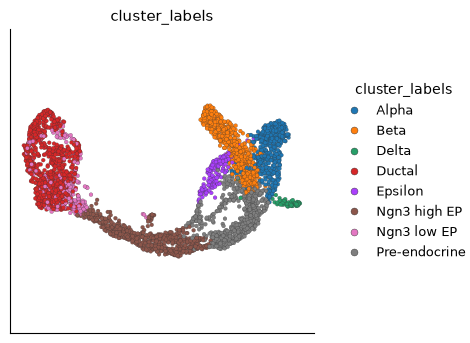

Started: 2026-10-22T16:52:25.433571Z | Wall time: 0.849 s

In [11]:
# Plot the imported UMAP using the cluster labels kept from H5AD.
ds.plots.embedding(
    layout=h5ad_import.embeddingArtifacts["X_umap"],
    color_by=h5ad_import.clusterArtifacts["clusters"],
)

In [12]:
# Choose a directory for the exported Matrix Market files.
mtx_export = output_dir / "diff_pancreas"

# Export the assay counts to Matrix Market files.
cytearc.writers.to_mtx(assay=ds.RNA, mtx_directory=str(mtx_export))

# List the exported files with their sizes in bytes.
[(path.name, path.stat().st_size) for path in sorted(mtx_export.iterdir())]

[('barcodes.tsv', 62832), ('genes.tsv', 865084), ('matrix.mtx', 114507260)]

Started: 2026-10-22T16:52:26.284422Z | Wall time: 2.624 s

## Export to H5AD and AnnData

`DataStore.to_anndata` builds an in-memory AnnData object from the selected counts and
metadata, and `cytearc.to_h5ad` streams the same kind of export into a file without AnnData.
Both export artifacts beside the counts: coordinates and embeddings as `obsm`, cell labels and
scores as `obs`, and a neighbour graph as `graph`. Each artifact must hold every exported cell,
so export the cells of the selection that the artifacts cover with `cell_selection`. Exporting
does not change the CyteArc store.

For a completed pipeline, prefer `ds.to_anndata(run=run)`. That form exports the run's frozen
assay, cell selection, feature selection, metadata, PCA, UMAP, and cluster labels. It rejects
live `cell_key`, `cell_selection`, `feature_indexes`, and `feature_names` overrides so the
exported axes cannot drift from the run.

### Export imported artifacts

In [13]:
# Export the imported cells with the imported UMAP in obsm and their labels in obs.
adata = ds.to_anndata(
    cell_selection=h5ad_import.cellSelection,
    obsm={"X_umap": h5ad_import.embeddingArtifacts["X_umap"]},
    obs={"clusters": h5ad_import.clusterArtifacts["clusters"]},
)

# Choose the exported H5AD filename.
h5ad_export = output_dir / "diff_pancreas.h5ad"

# Write counts, metadata, and the exported artifacts to H5AD.
adata.write_h5ad(h5ad_export)

# Confirm the written filename and its size in bytes.
{"file": h5ad_export.name, "bytes": h5ad_export.stat().st_size}

{'file': 'diff_pancreas.h5ad', 'bytes': 77932304}

Started: 2026-10-22T16:52:28.911717Z | Wall time: 1.256 s

Reload the H5AD and confirm that the layout is in `obsm` and that the labels are a categorical
with the categories, in their source order, and colors that the import kept:

In [14]:
# Reload the exported H5AD with AnnData.
import anndata as ad

# Reload the exported H5AD to verify its contents.
adata = ad.read_h5ad(h5ad_export)

# Verify the embedding, the label categories, and their colors.
{
    "obsm": sorted(adata.obsm.keys()),
    "umap shape": adata.obsm["X_umap"].shape,
    "cluster categories": adata.obs["clusters"].cat.categories.tolist(),
    "first cluster colors": adata.uns["clusters_colors"][:3].tolist(),
}

{'obsm': ['X_umap'],
 'umap shape': (3696, 2),
 'cluster categories': ['Ductal',
  'Ngn3 low EP',
  'Ngn3 high EP',
  'Pre-endocrine',
  'Beta',
  'Alpha',
  'Delta',
  'Epsilon'],
 'first cluster colors': ['#8fbc8f', '#f4a460', '#fdbf6f']}

Started: 2026-10-22T16:52:30.170280Z | Wall time: 0.108 s

### Round trip with Scanpy

Scanpy reads PCA coordinates from `obsm["X_pca"]`, a neighbour graph from `obsp` with
`uns["neighbors"]`, and cell groups from categorical `obs` columns. Build those results in
CyteArc, export them in Scanpy's layout, compute a new representation of the cells outside
CyteArc, and bring it back as graph coordinates. The outside step here uses scikit-learn, so this
page does not need Scanpy itself; a latent space from scVI or another tool returns the same way.

In [15]:
# Use the imported cells for the analysis.
cells = h5ad_import.cellSelection

# Select highly variable genes over those cells.
hvgs = ds.features.hvgs(cells, top_n=2000, show_plot=False)

# Normalize the selected genes.
normalized = ds.features.normalize(cells, hvgs)

# Reduce the normalized values with PCA.
pca = ds.reduction.pca(normalized, dims=20)

# Build the neighbour graph on the PCA coordinates.
graph = ds.graph.connectivity(ds.graph.neighbors(ds.graph.ann_index(pca), k=11))

# Embed the graph with UMAP, starting from a k-means initialization of the PCA.
umap = ds.embeddings.umap(graph, ds.embeddings.initialization(pca))

# Cluster the graph with Leiden.
leiden = ds.clusters.leiden(graph, resolution=1.0)

# Export the counts with the PCA, the UMAP, the Leiden labels, and the graph.
adata = ds.to_anndata(
    cell_selection=cells,
    obsm={"X_pca": pca, "X_umap": umap},
    obs={"leiden": leiden},
    graph=graph,
)

# List the elements that Scanpy reads.
{
    "obsm": sorted(adata.obsm.keys()),
    "obsp": sorted(adata.obsp.keys()),
    "varm": sorted(adata.varm.keys()),
    "neighbors": adata.uns["neighbors"]["params"],
    "leiden dtype": str(adata.obs["leiden"].dtype),
}

{'obsm': ['X_pca', 'X_umap'],
 'obsp': ['connectivities', 'distances'],
 'varm': ['PCs'],
 'neighbors': {'n_neighbors': 12,
  'method': 'umap',
  'metric': 'euclidean',
  'use_rep': 'X_pca'},
 'leiden dtype': 'category'}

Started: 2026-10-22T16:52:30.279995Z | Wall time: 55.829 s

`obs["leiden"]` is a categorical of text labels in natural order, so Scanpy groups by it as by
its own Leiden result, for example in `sc.tl.rank_genes_groups(adata, "leiden")`, and
`uns["neighbors"]` points `sc.tl.paga` and `sc.tl.leiden` at the exported graph without
`sc.pp.neighbors`. `varm["PCs"]` holds the PCA loadings, with zeros for the genes that the PCA
did not use. Here, count the cells of each cluster, and compute a new representation of the
cells from their counts of the PCA genes:

In [16]:
# Build sparse diagonal scaling matrices.
from scipy.sparse import csr_matrix, diags

# Fit a truncated SVD as the analysis step outside CyteArc.
from sklearn.decomposition import TruncatedSVD

# Count the cells of each Leiden cluster, as Scanpy groups by a categorical column.
cluster_sizes = adata.obs["leiden"].value_counts(sort=False)

# Find the genes that the PCA used, from their nonzero loadings.
pca_genes = adata.varm["PCs"].any(axis=1)

# Scale each cell's counts of those genes to 10,000 and log-transform them.
counts = csr_matrix(adata.X[:, pca_genes], dtype=np.float32)
scaled = diags(1e4 / np.maximum(counts.sum(axis=1).A1, 1)) @ counts
scaled.data = np.log1p(scaled.data)

# Compute a 15-dimensional latent space of the cells.
svd = TruncatedSVD(n_components=15, random_state=0)
adata.obsm["X_svd"] = svd.fit_transform(scaled)

# Show the cluster sizes and the shape of the latent space.
cluster_sizes.to_dict(), adata.obsm["X_svd"].shape

({'1': 510,
  '2': 387,
  '3': 304,
  '4': 263,
  '5': 227,
  '6': 227,
  '7': 207,
  '8': 198,
  '9': 193,
  '10': 179,
  '11': 174,
  '12': 166,
  '13': 143,
  '14': 127,
  '15': 124,
  '16': 91,
  '17': 89,
  '18': 87},
 (3696, 15))

Started: 2026-10-22T16:53:26.113450Z | Wall time: 0.166 s

Bring the latent space back as graph coordinates. `reduction.import_coordinates` aligns a
DataFrame to the selected cells by its index of cell IDs and records the tool that made it, so
lineage shows where the coordinates came from. Graph construction and clustering then use them
as they use a PCA:

In [17]:
# Record the version of the tool that computed the latent space.
import sklearn

# Import the latent space as coordinates of the same cells, with a record of its source.
latent = ds.reduction.import_coordinates(
    pd.DataFrame(adata.obsm["X_svd"], index=adata.obs_names),
    cell_selection=cells,
    name="X_svd",
    source={
        "tool": "scikit-learn TruncatedSVD",
        "version": sklearn.__version__,
        "parameters": {"n_components": 15, "random_state": 0},
    },
)

# Build a neighbour graph on the imported coordinates.
latent_graph = ds.graph.connectivity(
    ds.graph.neighbors(ds.graph.ann_index(latent), k=11)
)

# Cluster the new graph with Leiden.
latent_leiden = ds.clusters.leiden(latent_graph, resolution=1.0)

# Compare the clusters of both graphs cell by cell.
pd.crosstab(
    ds.artifacts.load_values(leiden).values,
    ds.artifacts.load_values(latent_leiden).values,
    rownames=["PCA Leiden"],
    colnames=["SVD Leiden"],
)

SVD Leiden,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18
PCA Leiden,,,,,,,,,,,,,,,,,,
1,460,0,0,0,0,0,0,32,0,14,0,0,0,4,0,0,0,0
2,0,364,0,14,0,0,0,0,4,0,0,0,0,0,0,0,5,0
3,0,0,119,177,0,0,1,0,2,0,0,0,0,0,5,0,0,0
4,0,0,0,0,11,245,0,0,0,0,0,0,0,0,0,7,0,0
5,0,9,0,108,0,0,110,0,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,225,2,0,0,0,0,0,0,0,0,0,0,0,0
7,43,0,0,0,0,0,0,3,0,0,0,0,103,58,0,0,0,0
8,0,2,167,1,0,27,0,0,0,0,0,0,0,0,0,1,0,0
9,0,8,0,0,0,0,0,0,182,0,0,0,0,0,0,3,0,0


Started: 2026-10-22T16:53:26.281296Z | Wall time: 0.681 s

Each row is a cluster of the PCA graph and each column a cluster of the graph built on the
imported coordinates. The imported artifact's provenance keeps the source record:
`ds.artifacts.inspect(latent).parameters["source"]` names the tool, its version, and its
parameters.

### Export a feature panel with `to_anndata`

Full-assay export can require enough memory and disk for the selected cell by feature matrix.
When only a marker panel is needed, select features before materializing AnnData.
Resolve the requested display names against the store once, then export only those columns:

In [18]:
# Read the feature names available in the store.
all_names = ds.RNA.feats.fetch_all("names").astype(str)

# Match requested genes without depending on letter case.
name_lookup = {name.upper(): name for name in all_names}

# Resolve the small marker panel against the stored gene names.
panel = [name_lookup[gene] for gene in ("GCG", "SST", "KRT19")]

# Export only the requested features into memory.
selected = ds.to_anndata(from_assay="RNA", matrix="raw", feature_names=panel)

# Check the exported dimensions and gene order.
{
    "shape": selected.shape,
    "genes": selected.var["names"].tolist(),
}

{'shape': (3696, 3), 'genes': ['Gcg', 'Sst', 'Krt19']}

Started: 2026-10-22T16:53:26.964150Z | Wall time: 0.212 s

Use `feature_indexes` instead when stable feature rows are already available.
`feature_names` and `feature_indexes` are mutually exclusive, preserve the requested order, and reject duplicate or unknown selections.

This export contains the selected genes' raw counts and live metadata for cells selected by
`I`. Omitting the feature selection exports every gene in the assay, while the cell selection
still applies. Saved analytical artifacts are not attached automatically in this form; add the
needed values to the AnnData object as above.

## Import CSV

`CSVReader` and `CSVtoZarr` provide small-data compatibility for dense CSV count matrices.
The toy matrix below is synthesized in-notebook so the conversion does not depend on a catalog file.
Rows are cells and columns are features; `cell_data_cols` moves selected columns into cell metadata.

In [19]:
# Choose a filename for the small CSV example.
csv_path = output_dir / "toy_counts.csv"

# Write the small example count table.
csv_path.write_text(
    "quality,geneA,geneB,geneC\n"
    "10,1,0,2\n"
    "20,0,3,0\n"
    "30,4,5,6\n"
    "40,7,0,8\n"
    "50,9,10,0\n",
    encoding="utf-8",
)

# Inspect the example CSV before conversion.
print(csv_path.read_text(encoding="utf-8"))

quality,geneA,geneB,geneC
10,1,0,2
20,0,3,0
30,4,5,6
40,7,0,8
50,9,10,0



Started: 2026-10-22T16:53:27.178094Z | Wall time: 0.005 s

Convert the CSV, keeping `quality` as cell metadata:

In [20]:
# Choose where to write the converted CSV store.
csv_zarr = output_dir / "toy_csv.zarr"

# Open a reader for the selected source format.
reader = cytearc.CSVReader(
    str(csv_path),
    cell_data_cols=["quality"],
)

# Write the converted count store.
cytearc.CSVtoZarr(reader, zarr_loc=str(csv_zarr), assay_name="RNA").dump()

# Open the converted CSV store.
ds_csv = cytearc.DataStore(str(csv_zarr))

# Inspect the first few rows of the result.
ds_csv.cells.head()

/tmp/ipykernel_4/821233974.py:14: UserWarning: 5 of 5 active cells have at most 10 features in assay 'RNA'. Will not remove low quality cells automatically, because that would remove at least half of the active cells. A default assay with few features, such as a small antibody panel, does this; later opens of this store do not filter it again. If this is a raw (unfiltered) droplet matrix, most of its barcodes are empty droplets, and bounds computed over them keep the empty droplets and remove the real cells: call cells first with qc.call_cells, or import the filtered matrix (for example Cell Ranger's filtered_feature_bc_matrix), before QC filtering.
  ds_csv = cytearc.DataStore(str(csv_zarr))


,I,ids,names,RNA_nCounts,RNA_nFeatures,quality
0,True,cell_0,cell_0,3.0,2.0,10
1,True,cell_1,cell_1,3.0,1.0,20
2,True,cell_2,cell_2,15.0,3.0,30
3,True,cell_3,cell_3,15.0,2.0,40
4,True,cell_4,cell_4,19.0,2.0,50


Started: 2026-10-22T16:53:27.185082Z | Wall time: 0.680 s

`quality` is cell metadata rather than a count column, which is what `cell_data_cols` is for.
Opening the store also warns that all five cells have at most 10 features. The first open of a
store removes such cells from `I`, unless that would remove at least half of the active cells, as
here; then it keeps them all and warns instead. The warning is expected for a three-gene toy
matrix, and its advice about raw droplet matrices does not apply. Open a store whose default
assay has few features, such as an antibody panel, with `min_features_per_cell=-1`, as
[](hto_demultiplexing.ipynb) does.

## Import sparse matrices

`SparseToZarr` accepts a SciPy CSR matrix with matching cell and feature IDs.

In [21]:
# Construct a small sparse count matrix.
from scipy.sparse import csr_matrix

# Construct a small sparse cell-by-feature count matrix.
mat = csr_matrix(
    (
        [1, 10, 15, 10, 20, 2, 3, 1, 5],
        ([0, 0, 0, 1, 1, 1, 2, 2, 2], [1, 3, 8, 2, 3, 1, 2, 8, 9]),
    ),
    shape=(3, 10),
)

# Display the three-cell toy matrix before conversion.
mat.toarray()

array([[ 0,  1,  0, 10,  0,  0,  0,  0, 15,  0],
       [ 0,  2, 10, 20,  0,  0,  0,  0,  0,  0],
       [ 0,  0,  3,  0,  0,  0,  0,  0,  1,  5]])

Started: 2026-10-22T16:53:27.868028Z | Wall time: 0.013 s

Write this small matrix with matching cell and feature identifiers:

In [22]:
# Choose where to write the sparse-matrix example.
sparse_zarr = output_dir / "toy_sparse.zarr"

# Write the converted count store.
cytearc.SparseToZarr(
    mat,
    zarr_loc=str(sparse_zarr),
    cell_ids=[f"cell_{i}" for i in range(mat.shape[0])],
    feature_ids=[f"feat_{i}" for i in range(mat.shape[1])],
    assay_name="RNA",
).dump()

# Open the converted sparse-matrix store.
ds_sparse = cytearc.DataStore(str(sparse_zarr))

# Inspect the opened store's cells and features.
ds_sparse

/tmp/ipykernel_4/2906446954.py:14: UserWarning: 3 of 3 active cells have at most 10 features in assay 'RNA'. Will not remove low quality cells automatically, because that would remove at least half of the active cells. A default assay with few features, such as a small antibody panel, does this; later opens of this store do not filter it again. If this is a raw (unfiltered) droplet matrix, most of its barcodes are empty droplets, and bounds computed over them keep the empty droplets and remove the real cells: call cells first with qc.call_cells, or import the filtered matrix (for example Cell Ranger's filtered_feature_bc_matrix), before QC filtering.
  ds_sparse = cytearc.DataStore(str(sparse_zarr))


DataStore has 3 (3) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures'
   RNA assay has 10 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'nCells'

Started: 2026-10-22T16:53:27.883522Z | Wall time: 0.301 s

Opening this store gives the same warning for the same reason: each of its three cells has three
features.

For a complete `DataStoreMerge` example, continue to [](dataset_merging.ipynb).

## Other import paths

### Chunked arrays

`chunked_to_zarr` writes from a CyteArc `ChunkedArray` when lazy out-of-core conversion is needed.

### Remote Zarr destinations

Writers also accept remote Zarr locations.
Choose the `cloud` profile for an object-store destination and pass credentials through the environment or runtime configuration:

```python
# Read object-store credentials from the environment.
import os

# Inspect the available count matrices and metadata.
inspection = cytearc.inspect_h5ad("counts.h5ad")

# Open a reader for the selected source format.
reader = cytearc.H5adReader.from_inspect(inspection)

# Configure a writer for the remote destination.
writer = cytearc.H5adToZarr(
    reader,
    zarr_loc="s3://my-bucket/project/data.zarr",
    storage_options={
        "access_key_id": os.environ["AWS_ACCESS_KEY_ID"],
        "secret_access_key": os.environ["AWS_SECRET_ACCESS_KEY"],
    },
    profile="cloud",
)

# Write the converted count store.
writer.dump()
```

### Count storage and memory

Writers choose the count dtype from the values, and RNA stores keep both cell-major `counts`
and gene-major `countsT` arrays. Start with the default storage layout: if an import cannot fit
its `mem_budget`, the error names a smaller `CountMatrixPolicy` that fits, as in the ATAC
example above. Prefer a larger memory budget when your machine allows it, because smaller RNA
shards slow later gene-major reads. See [](../concepts/memory_and_execution.md) for memory
planning and the [Import and export API reference](/api/import_export.html) for reader
buffering and storage options.

## Common mistakes and limitations

- Give every store its own fresh directory outside other stores: Writers raise `FileExistsError` for a path holding data and `ValueError` for nested paths like `data.zarr/RNA`; `overwrite=True` replaces only an earlier conversion no `DataStore` has opened, so delete a prepared store yourself or choose another path.
- Inspect the source instead of assuming what it holds or that CyteArc can read it: Confirm which H5AD layer contains raw counts before conversion, re-import older RNA stores that lack `countsT`, and remember Seurat import covers counts, metadata, and reductions - not neighbour graphs, images, normalized layers, or `.h5seurat`.
- CyteArc moves exactly what you select. Stored count dtype follows the values rather than a reader argument; analytical H5AD values become artifacts only when you name `embedding_roles` or `cluster_keys`; embeddings must be dense, numeric, row-aligned `obsm` arrays; keep `matrix="raw"` unless the receiving method calls for normalized expression; and export a feature panel rather than materializing a full AnnData when a panel answers the question.
